# HOT Cloud Detection - Labeled Scenes Demo

**Demonstration of HOT cloud detection on labeled scenes from data/labeled_scenes.csv.**

This notebook loads scenes with labeled Maxar cloud masks (548 tiles across 8 events with 20%+ cloud cover). It applies HOT detection and scores against ground truth masks.

**Note:** Calibrate a threshold here, then run `scripts/runner_hot.py` to process every scene and score the held-out split.

## 1. Setup

In [1]:
%pip install -q numpy pandas rasterio matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from pathlib import Path
import sys
import json

print("Libraries imported!")


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Libraries imported!


## 2. Load Labeled Scenes from CSV

In [2]:
# Find the repository root whether Jupyter started in the repo or notebooks/.
def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data" / "labeled_scenes.csv").is_file() and (
            candidate / "src" / "methods" / "hot_detect.py"
        ).is_file():
            return candidate
    raise FileNotFoundError(
        "Could not find the repository root. Start Jupyter in the repository or one of its subfolders."
    )

ROOT = find_repo_root()
labeled_scenes = pd.read_csv(ROOT / "data" / "labeled_scenes.csv")
print(f"Repository: {ROOT}")
print(f"Total labeled scenes: {len(labeled_scenes)}")
print("\nEvents in dataset:")
print(labeled_scenes["event"].value_counts())
print(
    f"\nCSV cloud-cover range: {labeled_scenes['cloud_percent'].min()}% - "
    f"{labeled_scenes['cloud_percent'].max()}%"
)
print("\nTop 5 cloudiest scenes:")
print(labeled_scenes.nlargest(5, "cloud_percent")[
    ["event", "item_id", "cloud_percent"]
])

Repository: /workspaces/Ursa-Space-Systems-1B-cloud-detection-in-very-high-resolution-optical-satellite-imagery
Total labeled scenes: 548

Events in dataset:
event
tonga-volcano21                        200
cyclone-emnati22                       173
HurricaneMilton-Oct24                   50
ghana-explosion22                       45
southafrica-flooding22                  34
HurricaneHelene-Oct24                   29
Hurricane-Maria-PuertoRico-Oct-2017     16
Cyclone-Chido-Dec15                      1
Name: count, dtype: int64

CSV cloud-cover range: 20% - 100%

Top 5 cloudiest scenes:
                     event                           item_id  cloud_percent
47   HurricaneMilton-Oct24  17/031331013223/10300100F54C6000            100
54   HurricaneMilton-Oct24  17/031331031001/10300100F54C6000            100
368        tonga-volcano21   1/300222121130/10300100CB37CA00            100
369        tonga-volcano21   1/300222121131/10300100CB37CA00            100
371        tonga-volcano21

## 3. Define Helper Functions

In [4]:
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.eval import evaluate
from src.methods.hot_data import (
    UnsupportedImageError,
    load_cloud_mask,
    load_rgb_at_shape,
)
from src.methods.hot_detect import detect_hot, hot_index
from src.methods.hot_validation import assign_scene_splits, threshold_f1_scores

print("HOT detector and shared raster helpers imported")

HOT detector and shared raster helpers imported


## 4. Calibrate threshold on a separate scene split

This uses a deterministic 20% per-event tuning split. Threshold is selected by mean per-scene F1, using only tuning scenes with both labeled cloud and clear pixels. The remaining scenes are held out for scoring; the threshold is not selected on them.

Run this cell before running `scripts/runner_hot.py`. It writes the selected threshold and scene IDs to `results/hot_threshold.json`.


In [5]:
TUNING_FRACTION = 0.20
SPLIT_SEED = 42
THRESHOLD_CANDIDATES = np.round(np.arange(-1.0, 1.001, 0.01), 2)

scene_split = assign_scene_splits(labeled_scenes, TUNING_FRACTION, SPLIT_SEED)
tuning_rows = labeled_scenes[
    labeled_scenes["item_id"].astype(str).map(scene_split) == "tuning"
]
evaluation_rows = labeled_scenes[
    labeled_scenes["item_id"].astype(str).map(scene_split) == "evaluation"
]

f1_sums = np.zeros(len(THRESHOLD_CANDIDATES), dtype=np.float64)
calibration_item_ids = []
calibration_excluded = {}

for _, row in tuning_rows.iterrows():
    item_id = str(row["item_id"])
    try:
        mask = load_cloud_mask(row["mask_href"])
        valid = mask != 0
        if not valid.any():
            raise ValueError("mask has no labeled pixels")
        truth = mask == 2
        if np.unique(truth[valid]).size < 2:
            raise ValueError("tuning mask must contain both clear and cloud pixels")
        image = load_rgb_at_shape(row["visual_href"], mask.shape)
        scores = hot_index(image)
        f1_sums += threshold_f1_scores(
            scores, truth, valid, THRESHOLD_CANDIDATES
        )
        calibration_item_ids.append(item_id)
    except Exception as error:
        calibration_excluded[item_id] = str(error)
        print(f"Excluded from threshold tuning: {item_id}: {error}")

if not calibration_item_ids:
    raise ValueError(
        "No usable calibration scenes. Need RGB visuals and masks containing "
        "both clear and cloud pixels."
    )

mean_f1 = f1_sums / len(calibration_item_ids)
best_f1 = float(mean_f1.max())
best_index = max(
    (i for i, score in enumerate(mean_f1) if np.isclose(score, best_f1)),
    key=lambda i: THRESHOLD_CANDIDATES[i],
)
HOT_THRESHOLD = float(THRESHOLD_CANDIDATES[best_index])

calibration = {
    "schema_version": 1,
    "threshold": HOT_THRESHOLD,
    "threshold_candidates": THRESHOLD_CANDIDATES.tolist(),
    "tuning_fraction": TUNING_FRACTION,
    "split_seed": SPLIT_SEED,
    "objective": "mean per-scene F1; highest threshold wins ties",
    "tuning_macro_f1": best_f1,
    "calibration_item_ids": calibration_item_ids,
    "evaluation_item_ids": [
        str(item_id) for item_id in evaluation_rows["item_id"]
    ],
    "calibration_excluded": calibration_excluded,
}
calibration_path = ROOT / "results" / "hot_threshold.json"
calibration_path.parent.mkdir(parents=True, exist_ok=True)
calibration_path.write_text(json.dumps(calibration, indent=2) + "\n")

print(f"Tuning scenes used: {len(calibration_item_ids)}")
print(f"Tuning scenes excluded: {len(calibration_excluded)}")
print(f"Held-out evaluation scenes: {len(evaluation_rows)}")
print(f"Selected HOT threshold: {HOT_THRESHOLD:.2f}")
print(f"Tuning mean per-scene F1: {best_f1:.4f}")
print(f"Saved calibration to {calibration_path}")

Excluded from threshold tuning: 36/213131021131/10200100C3078400: HOT requires an RGB visual with at least 3 bands; https://maxar-opendata.s3.amazonaws.com/events/southafrica-flooding22/ard/36/213131021131/2022-04-14/10200100C3078400-visual.tif has 1
Excluded from threshold tuning: 36/213131030020/10200100C3078400: HOT requires an RGB visual with at least 3 bands; https://maxar-opendata.s3.amazonaws.com/events/southafrica-flooding22/ard/36/213131030020/2022-04-14/10200100C3078400-visual.tif has 1
Tuning scenes used: 108
Tuning scenes excluded: 2
Held-out evaluation scenes: 438
Selected HOT threshold: -0.08
Tuning mean per-scene F1: 0.6874
Saved calibration to /workspaces/Ursa-Space-Systems-1B-cloud-detection-in-very-high-resolution-optical-satellite-imagery/results/hot_threshold.json


In [6]:
# Inspect one calibration scene only; do not adjust the threshold from held-out results.
test_row = labeled_scenes[
    labeled_scenes["item_id"].astype(str).isin(calibration_item_ids)
].iloc[0]

print("Inspecting a calibration scene...")
print(f"Scene: {test_row['item_id']}")
mask = load_cloud_mask(test_row["mask_href"])
valid = mask != 0
image = load_rgb_at_shape(test_row["visual_href"], mask.shape)
truth = mask == 2
pred = detect_hot(image, threshold=HOT_THRESHOLD)
print(f"Mask shape: {mask.shape}")
print(f"Mask values: {np.unique(mask)}")
print(f"Labeled-pixel fraction: {valid.mean() * 100:.1f}%")
print(f"Cloud fraction among labeled pixels: {truth[valid].mean() * 100:.1f}%")
print(f"Predicted cloud at selected threshold: {pred[valid].mean() * 100:.1f}%")

Inspecting a calibration scene...
Scene: 19/122002311232/105001000B8E2F00
Mask shape: (2176, 2176)
Mask values: [0 1 2 3]
Labeled-pixel fraction: 18.0%
Cloud fraction among labeled pixels: 21.5%
Predicted cloud at selected threshold: 96.2%


## 6. Process Held-Out Sample Scenes

In [7]:
# Show up to three held-out scenes with both clear and cloud labels.
results = []
for _, row in evaluation_rows.sort_values("cloud_percent", ascending=False).iterrows():
    item_id = str(row["item_id"])
    mask = load_cloud_mask(row["mask_href"])
    valid = mask != 0
    if not valid.any() or np.unique((mask == 2)[valid]).size < 2:
        continue

    try:
        image = load_rgb_at_shape(row["visual_href"], mask.shape)
    except UnsupportedImageError as error:
        print(f"Skipping unsupported demo scene {item_id}: {error}")
        continue

    pred = detect_hot(image, threshold=HOT_THRESHOLD)
    scores = evaluate(pred, mask == 2, valid)
    results.append({
        "event": row["event"],
        "item_id": item_id,
        "cloud_percent": row["cloud_percent"],
        "image": image,
        "mask": mask,
        "pred": pred,
        "scores": scores,
    })
    if len(results) == 3:
        break

if not results:
    raise ValueError("No held-out RGB scenes with both clear and cloud labels were found")
print(f"Displayed {len(results)} held-out scenes; threshold={HOT_THRESHOLD:.2f}")

Displayed 3 held-out scenes; threshold=-0.08


## 7. Visualize Results

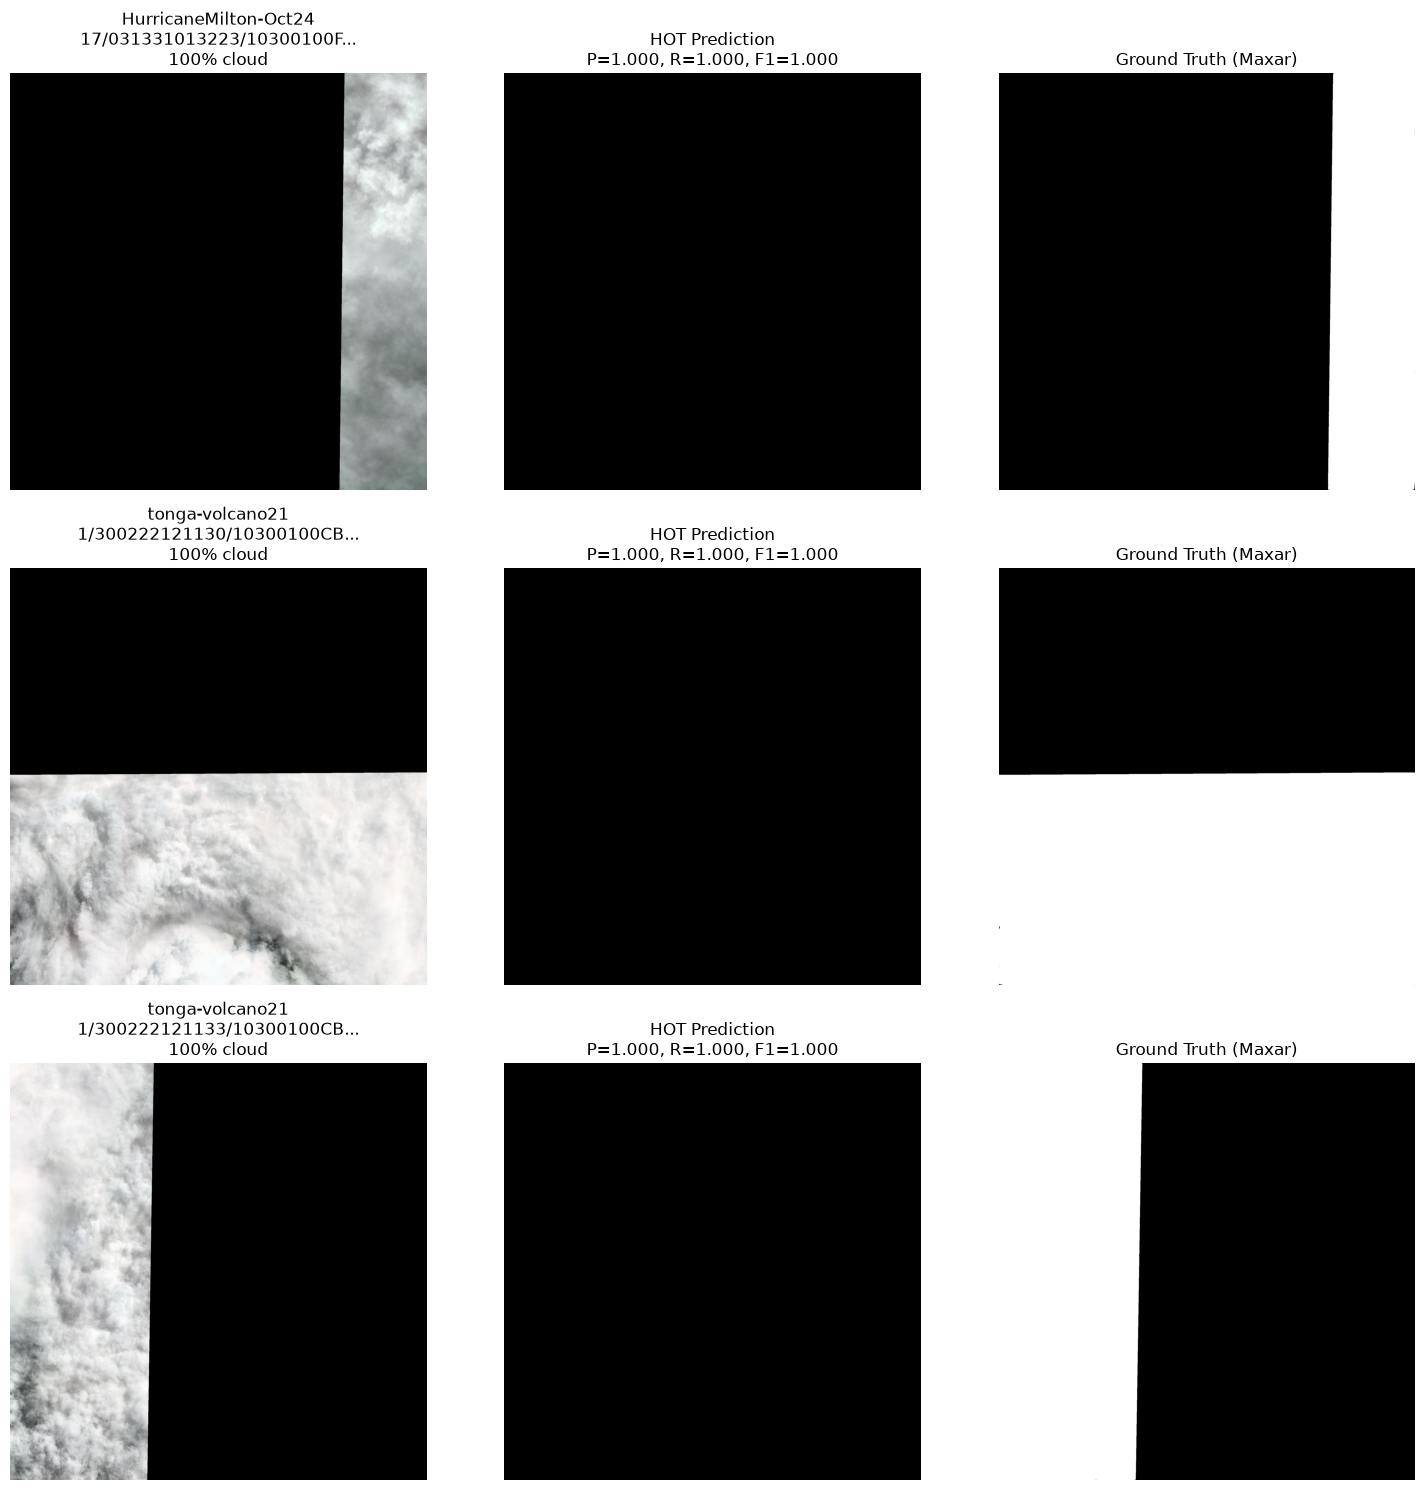

In [8]:
fig, axes = plt.subplots(len(results), 3, figsize=(15, 5*len(results)))
if len(results) == 1:
    axes = axes.reshape(1, -1)

for idx, result in enumerate(results):
    # Original RGB
    axes[idx, 0].imshow(result['image'])
    axes[idx, 0].set_title(f"{result['event']}\n{result['item_id'][:25]}...\n{result['cloud_percent']:.0f}% cloud")
    axes[idx, 0].axis('off')
    
    # HOT prediction
    axes[idx, 1].imshow(result['pred'], cmap='gray')
    axes[idx, 1].set_title(f"HOT Prediction\nP={result['scores']['precision']:.3f}, R={result['scores']['recall']:.3f}, F1={result['scores']['f1']:.3f}")
    axes[idx, 1].axis('off')
    
    # Ground truth (mask == 2 is cloud)
    axes[idx, 2].imshow(result['mask'] == 2, cmap='gray')
    axes[idx, 2].set_title("Ground Truth (Maxar)")
    axes[idx, 2].axis('off')

plt.tight_layout()
plt.show()

## 8. Summary

In [9]:
print("HOT Detection Results - Sample Labeled Scenes")
print("=" * 70)

for result in results:
    valid = result["mask"] != 0
    print(f"\nEvent: {result['event']}")
    print(f"  Scene ID: {result['item_id']}")
    print(f"  CSV cloud cover: {result['cloud_percent']:.0f}%")
    print(f"  Mask cloud cover among labeled pixels: {(result['mask'][valid] == 2).mean() * 100:.1f}%")
    print(f"  Predicted cloud among labeled pixels: {result['pred'][valid].mean() * 100:.1f}%")
    print(f"  Precision: {result['scores']['precision']:.3f}")
    print(f"  Recall: {result['scores']['recall']:.3f}")
    print(f"  F1 Score: {result['scores']['f1']:.3f}")

print("\n" + "=" * 70)
print("After calibration, run: python scripts/runner_hot.py (scores held-out scenes only)")

HOT Detection Results - Sample Labeled Scenes

Event: HurricaneMilton-Oct24
  Scene ID: 17/031331013223/10300100F54C6000
  CSV cloud cover: 100%
  Mask cloud cover among labeled pixels: 100.0%
  Predicted cloud among labeled pixels: 100.0%
  Precision: 1.000
  Recall: 1.000
  F1 Score: 1.000

Event: tonga-volcano21
  Scene ID: 1/300222121130/10300100CB37CA00
  CSV cloud cover: 100%
  Mask cloud cover among labeled pixels: 100.0%
  Predicted cloud among labeled pixels: 100.0%
  Precision: 1.000
  Recall: 1.000
  F1 Score: 1.000

Event: tonga-volcano21
  Scene ID: 1/300222121133/10300100CB37CA00
  CSV cloud cover: 100%
  Mask cloud cover among labeled pixels: 100.0%
  Predicted cloud among labeled pixels: 100.0%
  Precision: 1.000
  Recall: 1.000
  F1 Score: 1.000

After calibration, run: python scripts/runner_hot.py (scores held-out scenes only)


**This notebook:**
- Reads 548 labeled scenes from data/labeled_scenes.csv.
- Calibrates HOT threshold on a deterministic, event-stratified 20% tuning split.
- Selects threshold by mean per-scene F1 on tuning scenes that contain both clear and cloud labels.
- Saves the threshold and split to results/hot_threshold.json. Run scripts/runner_hot.py to score the separate holdout split.
- Marks calibration-only, excluded, unsupported, and failed scenes explicitly; only held-out scored rows are evaluation metrics.

The masks come from Maxar's cloud model, so the scores measure agreement with that model, not ground-truth accuracy.

## Interpretation and limitations

Cloud percentages and scores use only mask pixels with value 1 (clear) or 2 (cloud); value 0 is unlabeled. A calibration scene must have both clear and cloud labels. The threshold is chosen only on the calibration split, and final reported scores belong to held-out scenes.

HOT requires three RGB bands. Single-band panchromatic images are marked unsupported rather than being treated as RGB. The masks come from Maxar's cloud model, so agreement scores are not independent ground-truth accuracy.